# Phase 2 · Hyper-parameter optimisation

Tunes the three phase 1 architectures (Logistic Regression, Naive Bayes, Decision Tree), adds the two tree ensembles recommended by the brief (Random Forest and Gradient Boosting) and the other required architectures, K-Nearest Neighbors, a Support Vector Machine and an Artificial Neural Network (multilayer perceptron), with a most-frequent `DummyClassifier` as the floor. Every model uses the same holdout, the same 10 validations and the same objective, so their results are directly comparable.

- **Holdout test**: the phase 1 split (one of five polygon folds), untouched during tuning, so the results are comparable with phase 1.
- **Validation**: `StratifiedGroupKFold` on the training set, 5 folds repeated with 2 seeds = **10 validations** per candidate. Polygons are never split; the class proportions of every fold stay as close to the training set as whole polygons allow.
- **Objective**: macro-F1 over the classes with reference pixels (2 to 9; class 10 has a single polygon and cannot be validated). Accuracy, kappa and balanced accuracy are tracked alongside.
- **Search**: exhaustive finite grids. Random Forest, Gradient Boosting, K-Nearest Neighbors, the Support Vector Machine and the neural network are tuned on a class-stratified 25 % subsample of the training pixels with the same folds; every selected model is then refit on the full training set.
- **Outputs**: `outputs/phase2/` and one MLflow run per model (`phase2-<model>`).

In [1]:
import ast
import gc
import io
import json
import os
import time
import warnings
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import skops.io as sio
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, cohen_kappa_score,
    confusion_matrix, f1_score, make_scorer, precision_recall_fscore_support,
)
from sklearn.model_selection import GridSearchCV, ParameterGrid, StratifiedGroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sqlalchemy import URL, create_engine, text

# The parallel workers of the search import the feature transformer from this folder.
os.environ["PYTHONPATH"] = os.pathsep.join(filter(None, [str(Path.cwd()), os.environ.get("PYTHONPATH")]))
from sentinel2_features import BANDS as FEATURE_BANDS, ClassWeightedClassifier, SpectralFeatures

DATASET = "T18NWL_20260810T152649"
BANDS = [band.strip() for band in os.environ["BAND_NAMES"].split(",")]
assert tuple(BANDS) == FEATURE_BANDS, "band order differs from sentinel2_features.BANDS"
SEED = 42
HOLDOUT_FOLDS = 5          # same holdout as phase 1: one fold of five polygons groups
CV_FOLDS = 5               # validation folds inside the training set
CV_SEEDS = [SEED, SEED + 1]  # 2 repetitions -> 10 validations per candidate
SUBSAMPLE_FRACTION = 0.25  # training pixels used to tune Random Forest, Gradient Boosting, KNN, SVM and the MLP
N_JOBS = 4                 # parallel candidates; the container has 10 cores and ~8 GB of RAM
OUTPUTS = Path("outputs/phase2")
OUTPUTS.mkdir(parents=True, exist_ok=True)
PROGRESS = OUTPUTS / "progress.log"
PROGRESS.write_text("")

CLASS_NAMES = {
    0: "No data", 1: "Saturated or defective", 2: "Dark area pixels", 3: "Cloud shadows",
    4: "Vegetation", 5: "Not vegetated", 6: "Water", 7: "Unclassified",
    8: "Cloud medium probability", 9: "Cloud high probability", 10: "Thin cirrus", 11: "Snow",
}
# Metric warnings for classes absent from a fold (class 10) are expected and handled with labels=.
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")


def log(message):
    stamp = time.strftime("%H:%M:%S")
    print(f"[{stamp}] {message}", flush=True)
    with PROGRESS.open("a") as handle:
        handle.write(f"[{stamp}] {message}\n")

## 1. Load the training dataset

Same source and polygon join as phase 1.

In [2]:
s3 = boto3.client("s3", endpoint_url=os.environ["MLFLOW_S3_ENDPOINT_URL"])
body = s3.get_object(Bucket=os.environ["DATA_BUCKET"], Key=f"tsv/{DATASET}.tsv")["Body"].read()
samples = pd.read_csv(io.BytesIO(body), sep="\t", float_precision="round_trip")
assert list(samples.columns) == ["Latitude", "Longitude", *BANDS, "Class"], samples.columns

engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=os.environ["TRAIN_DB_USER"], password=os.environ["TRAIN_DB_PASSWORD"],
    host=os.environ["TRAIN_DB_HOST"], port=int(os.environ["TRAIN_DB_PORT"]),
    database=os.environ["TRAIN_DB_NAME"],
))
with engine.connect() as connection:
    polygons = pd.read_sql(
        text('SELECT latitude AS "Latitude", longitude AS "Longitude", fid '
             "FROM extracted.polygon_pixels WHERE dataset = :dataset"),
        connection, params={"dataset": DATASET},
    )
samples = samples.merge(polygons, on=["Latitude", "Longitude"], how="left", validate="one_to_one")
assert samples["fid"].notna().all(), "samples without a polygon"
log(f"{len(samples):,} samples, {samples['fid'].nunique():,} polygons")

[04:58:02] 583,835 samples, 11,711 polygons


## 2. Holdout test (phase 1 split)

In [3]:
X, y, groups = samples[BANDS], samples["Class"], samples["fid"]
train_index, test_index = next(
    StratifiedGroupKFold(n_splits=HOLDOUT_FOLDS, shuffle=True, random_state=SEED).split(X, y, groups)
)
X_train, y_train, g_train = (part.iloc[train_index].reset_index(drop=True) for part in (X, y, groups))
X_test, y_test = X.iloc[test_index].reset_index(drop=True), y.iloc[test_index].reset_index(drop=True)
assert not set(g_train) & set(groups.iloc[test_index]), "polygon on both sides"

phase1 = json.loads(Path("outputs/phase1/metrics.json").read_text())
assert (len(y_train), len(y_test)) == (phase1["train_samples"], phase1["test_samples"]), "split differs from phase 1"

EVAL_LABELS = sorted(y_test.unique())  # classes that can be evaluated (2 to 9)
TRAIN_LABELS = sorted(y_train.unique())
log(f"train {len(y_train):,} / test {len(y_test):,}; evaluated classes {EVAL_LABELS}")

[04:58:03] train 468,989 / test 114,846; evaluated classes [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


## 3. Validation folds balanced by class

`StratifiedGroupKFold` assigns whole polygons to folds while keeping the share of pixels of every class as close as possible to the training set. Two repetitions with different seeds give ten validations per candidate.

More folds were considered: with 10 folds the water class (11 training polygons, some of them large) drops to 11 pixels in one validation fold, so 5 folds × 2 repetitions keeps every fold balanced while doubling the number of validations.

In [4]:
splits, balance_rows = [], []
for repeat, seed in enumerate(CV_SEEDS):
    splitter = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=seed)
    for fold, (fit_index, val_index) in enumerate(splitter.split(X_train, y_train, g_train)):
        assert not set(g_train.iloc[fit_index]) & set(g_train.iloc[val_index]), "polygon on both sides"
        counts = y_train.iloc[val_index].value_counts()
        assert all(counts.get(label, 0) > 0 for label in EVAL_LABELS), f"fold without an evaluated class"
        splits.append((fit_index, val_index))
        balance_rows.append({"split": len(splits) - 1, "repeat": repeat, "fold": fold, "pixels": len(val_index),
                             **{label: int(counts.get(label, 0)) for label in TRAIN_LABELS}})

balance = pd.DataFrame(balance_rows).set_index("split")
balance.to_csv(OUTPUTS / "fold_balance.csv")

# Share of each class in every validation fold against its share in the whole training set.
shares = balance[TRAIN_LABELS].div(balance["pixels"], axis=0)
reference = y_train.value_counts(normalize=True).reindex(TRAIN_LABELS)
share_table = pd.DataFrame({"training share": reference, "min fold share": shares.min(), "max fold share": shares.max()})
share_table.index.name = "Class"
share_table.round(4).to_csv(OUTPUTS / "fold_class_shares.csv")
log(f"{len(splits)} validation splits; largest deviation of a class share: "
    f"{(shares - reference).abs().max().max():.4f}")
display(balance)
share_table.round(4)

[04:58:05] 10 validation splits; largest deviation of a class share: 0.0183


,repeat,fold,pixels,2,3,4,5,6,7,8,9,10
split,,,,,,,,,,,,
0,0,0,93141,658,4891,7417,68049,2638,1042,3590,4856,0
1,0,1,93238,658,4903,7417,68049,2728,1042,3590,4851,0
2,0,2,92581,655,4911,7417,69490,428,1042,3698,4940,0
3,0,3,94441,658,5707,7412,69494,1524,1041,3701,4855,49
4,0,4,95588,658,5757,7412,69489,446,1041,5932,4853,0
5,1,0,93141,658,4891,7417,68049,2638,1042,3590,4856,0
6,1,1,93238,658,4903,7417,68049,2728,1042,3590,4851,0
7,1,2,92581,655,4911,7417,69490,428,1042,3698,4940,0
8,1,3,94441,658,5707,7412,69494,1524,1041,3701,4855,49


,training share,min fold share,max fold share
Class,,,
2,0.0070,0.0069,0.0071
3,0.0558,0.0525,0.0604
4,0.0791,0.0775,0.0801
5,0.7347,0.7270,0.7506
6,0.0166,0.0046,0.0293
7,0.0111,0.0109,0.0113
8,0.0437,0.0385,0.0621
9,0.0519,0.0508,0.0534
10,0.0001,0.0000,0.0005


Random Forest, Gradient Boosting, K-Nearest Neighbors, the Support Vector Machine and the neural network are tuned on a class-stratified subsample that keeps the same fold assignment. K-Nearest Neighbors has no training cost, but every prediction compares a pixel with all the fit pixels, so its cost grows with the size of the training set; the cost of fitting a Support Vector Machine grows faster than the number of pixels.

In [5]:
subsample = np.sort(y_train.groupby(y_train).sample(frac=SUBSAMPLE_FRACTION, random_state=SEED).index.to_numpy())
position = np.full(len(y_train), -1)
position[subsample] = np.arange(len(subsample))
sub_splits = []
for fit_index, val_index in splits:
    fit_sub, val_sub = position[fit_index], position[val_index]
    sub_splits.append((fit_sub[fit_sub >= 0], val_sub[val_sub >= 0]))
X_sub, y_sub = X_train.iloc[subsample].reset_index(drop=True), y_train.iloc[subsample].reset_index(drop=True)
log(f"subsample {len(y_sub):,} pixels ({SUBSAMPLE_FRACTION:.0%} of every class)")

[04:58:05] subsample 117,248 pixels (25% of every class)


## 4. Search spaces

Every estimator is a pipeline so the learned preprocessing is fitted inside each fold. `features` is `SpectralFeatures` (`sentinel2_features.py`): the ten bands, optionally `log1p`, optionally followed by NDVI, NDWI, MNDWI, NDMI and NBR.

- **K-Nearest Neighbors** classifies a pixel by the vote of its *k* closest training pixels, so the distance must treat every band alike: the bands are standardised, and the search covers the feature set (log and indices change which pixels are close), the number of neighbours (few neighbours follow rare classes, many neighbours smooth the noise) and the vote weights (uniform or by inverse distance). The distance is Euclidean.
- **Support Vector Machine** (RBF kernel) separates the classes with the boundary that leaves the widest margin, after mapping the standardised pixels to a space where curved boundaries become possible. The search covers the feature set and `C`, which sets how strongly misclassified training pixels are penalised (a large `C` follows the training data more closely). `gamma`, the reach of each training pixel, is set by the `scale` rule from the variance of the features. A linear kernel was below the RBF kernel at every `C` in an earlier comparison on the same holdout, so it is not searched again.
- **Neural network** (multilayer perceptron, Adam, mini-batches of 512, early stopping on 10 % of the fit data). It always receives log-bands and indices, the preprocessing that worked best for the other continuous models: compressing the bright cloud values and giving the ratios explicitly makes the optimisation more stable. The search covers the architecture (one hidden layer of 64 units or two layers of 128 and 64), the L2 penalty `alpha` and `class_weight`, which `ClassWeightedClassifier` passes as sample weights because `MLPClassifier` has no `class_weight` of its own. A (256, 128) network was tried and dropped: a single fit took more than 10 minutes.

In [6]:
SCORING = {
    "f1_macro": make_scorer(f1_score, average="macro", labels=EVAL_LABELS, zero_division=0),
    "accuracy": "accuracy",
    "kappa": make_scorer(cohen_kappa_score),
    "balanced_accuracy": make_scorer(balanced_accuracy_score),
}

SEARCHES = {
    "dummy": ("Most frequent (baseline)", Pipeline([("model", DummyClassifier(strategy="most_frequent"))]), {}, "full"),
    "logistic_regression": (
        "Logistic Regression",
        Pipeline([("features", SpectralFeatures()), ("scale", StandardScaler()),
                  ("model", LogisticRegression(max_iter=3000))]),
        {"features__indices": [False, True], "model__C": [0.01, 0.1, 1, 10],
         "model__class_weight": [None, "balanced"]},
        "full",
    ),
    "naive_bayes": (
        "Naive Bayes",
        Pipeline([("features", SpectralFeatures()), ("model", GaussianNB())]),
        {"features__indices": [False, True], "features__log": [False, True],
         "model__var_smoothing": np.logspace(-12, -3, 10).tolist()},
        "full",
    ),
    "decision_tree": (
        "Decision Tree",
        Pipeline([("model", DecisionTreeClassifier(random_state=SEED))]),
        {"model__max_depth": [10, 15, 20, None], "model__min_samples_leaf": [1, 5, 20, 50],
         "model__criterion": ["gini", "entropy"], "model__class_weight": [None, "balanced"]},
        "full",
    ),
    "random_forest": (
        "Random Forest",
        Pipeline([("model", RandomForestClassifier(n_estimators=200, n_jobs=N_JOBS, random_state=SEED))]),
        {"model__max_depth": [20, None], "model__max_features": ["sqrt", 0.5],
         "model__min_samples_leaf": [1, 5], "model__class_weight": [None, "balanced_subsample"]},
        "subsample",
    ),
    "gradient_boosting": (
        "Gradient Boosting (HistGradientBoosting)",
        Pipeline([("model", HistGradientBoostingClassifier(
            max_iter=500, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=SEED))]),
        {"model__learning_rate": [0.05, 0.1, 0.2], "model__max_leaf_nodes": [31, 63, 127],
         "model__l2_regularization": [0.0, 1.0], "model__class_weight": [None, "balanced"]},
        "subsample",
    ),
    "knn": (
        "K-Nearest Neighbors",
        Pipeline([("features", SpectralFeatures()), ("scale", StandardScaler()),
                  ("model", KNeighborsClassifier())]),
        {"features__indices": [False, True], "features__log": [False, True],
         "model__n_neighbors": [5, 15, 25, 41], "model__weights": ["uniform", "distance"]},
        "subsample",
    ),
    "svm": (
        "Support Vector Machine",
        Pipeline([("features", SpectralFeatures()), ("scale", StandardScaler()),
                  ("model", SVC(kernel="rbf", gamma="scale", cache_size=500))]),
        {"features__indices": [False, True], "features__log": [False, True], "model__C": [10, 100, 1000]},
        "subsample",
    ),
    "neural_network": (
        "Neural Network (MLP)",
        Pipeline([("features", SpectralFeatures(indices=True, log=True)), ("scale", StandardScaler()),
                  ("model", ClassWeightedClassifier(MLPClassifier(
                      batch_size=512, learning_rate_init=1e-3, max_iter=300, early_stopping=True,
                      validation_fraction=0.1, n_iter_no_change=10, random_state=SEED)))]),
        {"model__estimator__hidden_layer_sizes": [(64,), (128, 64)],
         "model__estimator__alpha": [1e-4, 1e-3], "model__class_weight": [None, "balanced"]},
        "subsample",
    ),
}
pd.DataFrame([
    {"model": name, "candidates": int(np.prod([len(v) for v in grid.values()])) if grid else 1,
     "fits": (int(np.prod([len(v) for v in grid.values()])) if grid else 1) * len(splits), "data": data}
    for name, _, grid, data in SEARCHES.values()
])

,model,candidates,fits,data
0,Most frequent (baseline),1,10,full
1,Logistic Regression,16,160,full
2,Naive Bayes,40,400,full
3,Decision Tree,64,640,full
4,Random Forest,16,160,subsample
5,Gradient Boosting (HistGradientBoosting),36,360,subsample
6,K-Nearest Neighbors,32,320,subsample
7,Support Vector Machine,12,120,subsample
8,Neural Network (MLP),8,80,subsample


## 5. Grid search with the 10 validations

A search whose saved `cv_results_<model>.csv` holds exactly the current grid and the same 10 validations is read from that file instead of being run again: the data, folds and seeds are fixed, so it would give the same scores. Changing a grid triggers a new search for that model.


In [7]:
METRICS = list(SCORING)


def saved_search(key, grid, n_splits):
    # Reuse a saved search only if it holds exactly the current grid, in order, scored on the same number of validations.
    # The data, folds and seeds are fixed above, so a search with the same grid gives the same scores.
    path = OUTPUTS / f"cv_results_{key}.csv"
    if not path.exists():
        return None
    table = pd.read_csv(path)
    table["params"] = table["params"].map(ast.literal_eval)
    same_grid = table["params"].tolist() == list(ParameterGrid(grid))
    same_splits = all(f"split{i}_test_{m}" in table for i in range(n_splits) for m in METRICS)
    return table if same_grid and same_splits and f"split{n_splits}_test_f1_macro" not in table else None


searches = {}
for key, (name, estimator, grid, data) in SEARCHES.items():
    X_fit, y_fit, cv = (X_sub, y_sub, sub_splits) if data == "subsample" else (X_train, y_train, splits)
    started = time.time()
    table = saved_search(key, grid, len(cv))
    reused = table is not None
    if not reused:
        search = GridSearchCV(
            estimator, grid, scoring=SCORING, refit=False, cv=cv, return_train_score=True,
            n_jobs=1 if key == "random_forest" else N_JOBS, error_score="raise",
        )
        search.fit(X_fit, y_fit)
        table = pd.DataFrame(search.cv_results_)
        table.to_csv(OUTPUTS / f"cv_results_{key}.csv", index=False)
        del search
    seconds = time.time() - started

    best = int(table["mean_test_f1_macro"].idxmax())
    split_scores = [table.loc[best, f"split{i}_test_f1_macro"] for i in range(len(cv))]
    searches[key] = {
        "name": name, "data": data, "candidates": len(table), "reused": reused,
        "search_seconds": None if reused else round(seconds),
        "params": table.loc[best, "params"], "split_f1_macro": split_scores,
        **{f"cv_{m}_mean": float(table.loc[best, f"mean_test_{m}"]) for m in METRICS},
        **{f"cv_{m}_std": float(table.loc[best, f"std_test_{m}"]) for m in METRICS},
        "cv_train_f1_macro_mean": float(table.loc[best, "mean_train_f1_macro"]),
    }
    timing = "loaded from the saved search" if reused else f"in {seconds / 60:.1f} min"
    log(f"{name}: {len(table)} candidates x {len(cv)} validations {timing}; "
        f"best macro-F1 {searches[key]['cv_f1_macro_mean']:.4f} ± {searches[key]['cv_f1_macro_std']:.4f} "
        f"with {searches[key]['params']}")
    gc.collect()

(OUTPUTS / "best_params.json").write_text(json.dumps(
    {key: {"model": s["name"], "params": s["params"], "tuned_on": s["data"], "candidates": s["candidates"]}
     for key, s in searches.items()}, indent=2, default=str))

[04:58:05] Most frequent (baseline): 1 candidates x 10 validations loaded from the saved search; best macro-F1 0.1059 ± 0.0007 with {}


[04:58:05] Logistic Regression: 16 candidates x 10 validations loaded from the saved search; best macro-F1 0.6239 ± 0.0303 with {'features__indices': True, 'model__C': 1, 'model__class_weight': 'balanced'}


[04:58:05] Naive Bayes: 40 candidates x 10 validations loaded from the saved search; best macro-F1 0.6040 ± 0.0251 with {'features__indices': True, 'features__log': True, 'model__var_smoothing': 1e-06}


[04:58:05] Decision Tree: 64 candidates x 10 validations loaded from the saved search; best macro-F1 0.6754 ± 0.0373 with {'model__class_weight': None, 'model__criterion': 'gini', 'model__max_depth': None, 'model__min_samples_leaf': 20}


[04:58:05] Random Forest: 16 candidates x 10 validations loaded from the saved search; best macro-F1 0.7033 ± 0.0357 with {'model__class_weight': 'balanced_subsample', 'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 5}


[04:58:05] Gradient Boosting (HistGradientBoosting): 36 candidates x 10 validations loaded from the saved search; best macro-F1 0.7049 ± 0.0396 with {'model__class_weight': None, 'model__l2_regularization': 1.0, 'model__learning_rate': 0.1, 'model__max_leaf_nodes': 31}


[04:58:05] K-Nearest Neighbors: 32 candidates x 10 validations loaded from the saved search; best macro-F1 0.6935 ± 0.0304 with {'features__indices': False, 'features__log': True, 'model__n_neighbors': 5, 'model__weights': 'distance'}


[05:36:55] Support Vector Machine: 12 candidates x 10 validations in 38.8 min; best macro-F1 0.7307 ± 0.0416 with {'features__indices': False, 'features__log': True, 'model__C': 1000}


[05:36:55] Neural Network (MLP): 8 candidates x 10 validations loaded from the saved search; best macro-F1 0.7098 ± 0.0494 with {'model__class_weight': None, 'model__estimator__alpha': 0.0001, 'model__estimator__hidden_layer_sizes': (128, 64)}


2176

## 6. Refit on the full training set and evaluate on the holdout

The holdout was not used to choose anything above. Each selected configuration is refit on all 468,989 training pixels.

In [8]:
def holdout_metrics(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=EVAL_LABELS, average=None, zero_division=0)
    macro = precision_recall_fscore_support(y_true, y_pred, labels=EVAL_LABELS, average="macro", zero_division=0)
    weighted = precision_recall_fscore_support(y_true, y_pred, labels=EVAL_LABELS, average="weighted", zero_division=0)
    summary = {
        "overall_accuracy": accuracy_score(y_true, y_pred),
        "kappa": cohen_kappa_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_macro": macro[0], "recall_macro": macro[1], "f1_macro": macro[2],
        "precision_weighted": weighted[0], "recall_weighted": weighted[1], "f1_weighted": weighted[2],
    }
    per_class = pd.DataFrame({"precision": precision, "recall": recall, "f1": f1}, index=EVAL_LABELS)
    return summary, per_class


def trusted_types(model):
    # The model was built in this notebook; trust exactly the types skops reports as unknown.
    return sio.get_untrusted_types(data=sio.dumps(model))


mlflow.set_experiment(os.environ["MLFLOW_EXPERIMENT_NAME"])
results, per_class_f1, matrices = [], {}, {}
for key, search in searches.items():
    name = search["name"]
    model = clone(SEARCHES[key][1]).set_params(**search["params"])
    started = time.time()
    model.fit(X_train, y_train)
    fit_seconds = time.time() - started
    predicted = model.predict(X_test)
    summary, per_class = holdout_metrics(y_test, predicted)
    train_accuracy = accuracy_score(y_train, model.predict(X_train))

    matrix = pd.DataFrame(confusion_matrix(y_test, predicted, labels=TRAIN_LABELS), index=TRAIN_LABELS, columns=TRAIN_LABELS)
    matrix.index.name, matrix.columns.name = "reference", "predicted"
    matrix.to_csv(OUTPUTS / f"confusion_matrix_{key}.csv")
    matrices[key] = matrix
    per_class.insert(0, "name", per_class.index.map(CLASS_NAMES))
    per_class.index.name = "Class"
    per_class.round(4).to_csv(OUTPUTS / f"per_class_{key}.csv")
    per_class_f1[name] = per_class["f1"]

    figure, axis = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=EVAL_LABELS, normalize="true", values_format=".2f",
        cmap="Blues", colorbar=False, ax=axis)
    axis.set(title=f"{name} · OA {summary['overall_accuracy']:.3f} · macro-F1 {summary['f1_macro']:.3f}",
             xlabel="Predicted class", ylabel="Reference class")
    figure.tight_layout()
    figure.savefig(OUTPUTS / f"confusion_matrix_{key}.png", dpi=150)
    plt.close(figure)

    with mlflow.start_run(run_name=f"phase2-{key}") as run:
        mlflow.log_params({
            "phase": 2, "model": name, "dataset": DATASET, "bands": ",".join(BANDS), "seed": SEED,
            "holdout": f"StratifiedGroupKFold by polygon, 1 of {HOLDOUT_FOLDS} folds",
            "validation": f"StratifiedGroupKFold by polygon, {CV_FOLDS} folds x {len(CV_SEEDS)} seeds",
            "tuned_on": f"{search['data']} ({len(y_sub) if search['data'] == 'subsample' else len(y_train)} pixels)",
            "candidates": search["candidates"], "objective": "macro-F1 over classes " + ",".join(map(str, EVAL_LABELS)),
            **{k: str(v) for k, v in search["params"].items()},
        })
        mlflow.log_metrics({
            **{k: v for k, v in search.items() if k.startswith("cv_")},
            **{f"test_{k}": v for k, v in summary.items()},
            "train_accuracy": train_accuracy, "fit_seconds": fit_seconds,
        })
        for artifact in (f"confusion_matrix_{key}.png", f"confusion_matrix_{key}.csv",
                         f"per_class_{key}.csv", f"cv_results_{key}.csv"):
            mlflow.log_artifact(OUTPUTS / artifact)
        mlflow.sklearn.log_model(model, name="model", skops_trusted_types=trusted_types(model),
                                 code_paths=["sentinel2_features.py"])

    results.append({"key": key, "model": name, "tuned_on": search["data"],
                    "cv_f1_macro_mean": search["cv_f1_macro_mean"], "cv_f1_macro_std": search["cv_f1_macro_std"],
                    "cv_accuracy_mean": search["cv_accuracy_mean"], "cv_kappa_mean": search["cv_kappa_mean"],
                    **{f"test_{k}": v for k, v in summary.items()},
                    "train_accuracy": train_accuracy, "fit_seconds": round(fit_seconds, 1),
                    "mlflow_run_id": run.info.run_id})
    log(f"{name}: holdout OA {summary['overall_accuracy']:.4f}, kappa {summary['kappa']:.4f}, "
        f"macro-F1 {summary['f1_macro']:.4f} (train accuracy {train_accuracy:.4f})")
    del model
    gc.collect()

🏃 View run phase2-dummy at: http://mlflow:5000/#/experiments/2/runs/1f0adcf6ee9a4155997d743cd7ed1b40
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[05:36:59] Most frequent (baseline): holdout OA 0.7411, kappa 0.0000, macro-F1 0.1064 (train accuracy 0.7347)


🏃 View run phase2-logistic_regression at: http://mlflow:5000/#/experiments/2/runs/06f70a567f65470394dd7c9d4540db20
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[05:38:17] Logistic Regression: holdout OA 0.8457, kappa 0.6925, macro-F1 0.5787 (train accuracy 0.8558)


🏃 View run phase2-naive_bayes at: http://mlflow:5000/#/experiments/2/runs/a9af2249dede4acfbee12533f9ff5203
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[05:38:20] Naive Bayes: holdout OA 0.8442, kappa 0.6798, macro-F1 0.5914 (train accuracy 0.8527)


🏃 View run phase2-decision_tree at: http://mlflow:5000/#/experiments/2/runs/17ce7986657e42bdbf6ab75f82354974
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[05:38:26] Decision Tree: holdout OA 0.9182, kappa 0.8100, macro-F1 0.6443 (train accuracy 0.9454)


🏃 View run phase2-random_forest at: http://mlflow:5000/#/experiments/2/runs/3ccad7bf43034b6c92447bf4c7fe9a5b
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[05:39:47] Random Forest: holdout OA 0.9212, kappa 0.8253, macro-F1 0.6685 (train accuracy 0.9668)


🏃 View run phase2-gradient_boosting at: http://mlflow:5000/#/experiments/2/runs/e008ed186d1547cc8e0333c3df87813c
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[05:45:15] Gradient Boosting (HistGradientBoosting): holdout OA 0.9332, kappa 0.8445, macro-F1 0.6722 (train accuracy 0.9720)


🏃 View run phase2-knn at: http://mlflow:5000/#/experiments/2/runs/aa93ec99f4d345abb4459e5199b954b1
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[05:45:36] K-Nearest Neighbors: holdout OA 0.9221, kappa 0.8182, macro-F1 0.6426 (train accuracy 1.0000)


🏃 View run phase2-svm at: http://mlflow:5000/#/experiments/2/runs/15f4da5fa68b4866afae732460df00ff
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[06:37:57] Support Vector Machine: holdout OA 0.9356, kappa 0.8492, macro-F1 0.6848 (train accuracy 0.9515)


🏃 View run phase2-neural_network at: http://mlflow:5000/#/experiments/2/runs/3de062ccad07407ca2a377d1e48c5244
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[06:45:55] Neural Network (MLP): holdout OA 0.9329, kappa 0.8435, macro-F1 0.6725 (train accuracy 0.9495)


## 7. Comparison

The model is chosen by the **cross-validated macro-F1** (mean of the 10 validations), not by the holdout. The holdout columns are the independent estimate of the chosen configurations.

In [9]:
summary = pd.DataFrame(results).sort_values("cv_f1_macro_mean", ascending=False).reset_index(drop=True)
best_key = summary.loc[summary["key"] != "dummy", "key"].iloc[0]
summary["selected"] = summary["key"] == best_key
summary.drop(columns="key").to_csv(OUTPUTS / "summary.csv", index=False)

(OUTPUTS / "metrics.json").write_text(json.dumps({
    "dataset": DATASET, "train_samples": len(y_train), "test_samples": len(y_test),
    "validation": {"folds": CV_FOLDS, "seeds": CV_SEEDS, "splits": len(splits)},
    "subsample_pixels": len(y_sub), "evaluated_classes": EVAL_LABELS, "selected": best_key,
    "models": results,
}, indent=2, default=str))
log(f"selected by cross-validated macro-F1: {summary.loc[summary['selected'], 'model'].item()}")

columns = ["model", "cv_f1_macro_mean", "cv_f1_macro_std", "test_overall_accuracy", "test_kappa",
           "test_balanced_accuracy", "test_precision_macro", "test_recall_macro", "test_f1_macro",
           "test_f1_weighted", "train_accuracy", "selected"]
summary[columns].round(4)

[06:45:55] selected by cross-validated macro-F1: Support Vector Machine


,model,cv_f1_macro_mean,cv_f1_macro_std,test_overall_accuracy,test_kappa,test_balanced_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_weighted,train_accuracy,selected
0,Support Vector Machine,0.7307,0.0416,0.9356,0.8492,0.6608,0.7170,0.6608,0.6848,0.9330,0.9515,True
1,Neural Network (MLP),0.7098,0.0494,0.9329,0.8435,0.6536,0.6960,0.6536,0.6725,0.9309,0.9495,False
2,Gradient Boosting (HistGradientBoosting),0.7049,0.0396,0.9332,0.8445,0.6543,0.6973,0.6543,0.6722,0.9308,0.9720,False
3,Random Forest,0.7033,0.0357,0.9212,0.8253,0.6990,0.6470,0.6990,0.6685,0.9246,0.9668,False
4,K-Nearest Neighbors,0.6935,0.0304,0.9221,0.8182,0.6274,0.6650,0.6274,0.6426,0.9196,1.0000,False
5,Decision Tree,0.6754,0.0373,0.9182,0.8100,0.6314,0.6624,0.6314,0.6443,0.9159,0.9454,False
6,Logistic Regression,0.6239,0.0303,0.8457,0.6925,0.6794,0.5608,0.6794,0.5787,0.8748,0.8558,False
7,Naive Bayes,0.6040,0.0251,0.8442,0.6798,0.6441,0.5712,0.6441,0.5914,0.8681,0.8527,False
8,Most frequent (baseline),0.1059,0.0007,0.7411,0.0000,0.1250,0.0926,0.1250,0.1064,0.6309,0.7347,False


In [10]:
# Phase 1 (default parameters) against phase 2 (tuned) on the same holdout.
# Phase 1 macro-F1 is recomputed over the evaluated classes from its saved confusion matrices.
def macro_f1_from_matrix(path):
    matrix = pd.read_csv(path, index_col=0)
    matrix.columns = matrix.columns.astype(int)
    tp = np.array([matrix.loc[c, c] for c in EVAL_LABELS], dtype=float)
    predicted = matrix[EVAL_LABELS].sum(axis=0).to_numpy(dtype=float)   # every reference row
    reference = matrix.loc[EVAL_LABELS].sum(axis=1).to_numpy(dtype=float)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = np.divide(tp, reference, out=np.zeros_like(tp), where=reference > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(tp), where=precision + recall > 0)
    return f1.mean()

rows = []
for entry in phase1["models"]:
    tuned = next(r for r in results if r["key"] == entry["key"])
    rows.append({
        "model": entry["model"],
        "phase 1 OA": entry["overall_accuracy"], "phase 2 OA": tuned["test_overall_accuracy"],
        "phase 1 kappa": entry["kappa"], "phase 2 kappa": tuned["test_kappa"],
        "phase 1 macro-F1": macro_f1_from_matrix(f"outputs/phase1/confusion_matrix_{entry['key']}.csv"),
        "phase 2 macro-F1": tuned["test_f1_macro"],
    })
phase_comparison = pd.DataFrame(rows)
phase_comparison.to_csv(OUTPUTS / "phase1_vs_phase2.csv", index=False)
phase_comparison.round(4)

,model,phase 1 OA,phase 2 OA,phase 1 kappa,phase 2 kappa,phase 1 macro-F1,phase 2 macro-F1
0,Logistic Regression,0.9069,0.8457,0.7804,0.6925,0.5800,0.5787
1,Naive Bayes,0.7675,0.8442,0.5494,0.6798,0.4860,0.5914
2,Decision Tree,0.8996,0.9182,0.7695,0.8100,0.6067,0.6443


In [11]:
# F1 per class on the holdout.
f1_table = pd.DataFrame(per_class_f1)
f1_table.insert(0, "name", f1_table.index.map(CLASS_NAMES))
f1_table.index.name = "Class"
f1_table.round(3).to_csv(OUTPUTS / "f1_per_class.csv")
f1_table.round(3)

,name,Most frequent (baseline),Logistic Regression,Naive Bayes,Decision Tree,Random Forest,Gradient Boosting (HistGradientBoosting),K-Nearest Neighbors,Support Vector Machine,Neural Network (MLP)
Class,,,,,,,,,,
2,Dark area pixels,0.000,0.116,0.057,0.209,0.300,0.290,0.234,0.333,0.311
3,Cloud shadows,0.000,0.754,0.777,0.790,0.824,0.841,0.810,0.851,0.841
4,Vegetation,0.000,0.769,0.740,0.796,0.839,0.840,0.808,0.839,0.846
5,Not vegetated,0.851,0.928,0.929,0.968,0.969,0.974,0.970,0.975,0.974
6,Water,0.000,0.175,0.494,0.214,0.232,0.204,0.186,0.197,0.180
7,Unclassified,0.000,0.324,0.371,0.517,0.472,0.487,0.455,0.521,0.484
8,Cloud medium probability,0.000,0.622,0.458,0.714,0.749,0.778,0.724,0.804,0.795
9,Cloud high probability,0.000,0.942,0.906,0.946,0.963,0.964,0.953,0.959,0.949


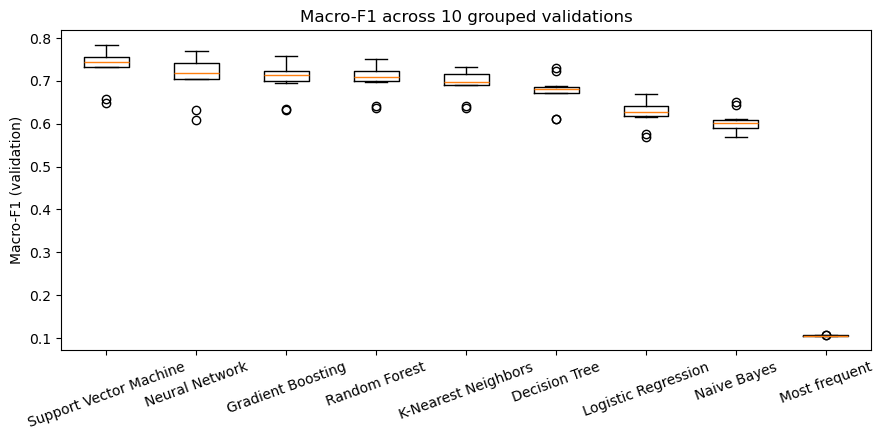

In [12]:
# Spread of the selected configuration of every model across the 10 validations.
order = summary["key"].tolist()
figure, axis = plt.subplots(figsize=(9, 4.5))
axis.boxplot([searches[k]["split_f1_macro"] for k in order], tick_labels=[searches[k]["name"].split(" (")[0] for k in order])
axis.set(ylabel="Macro-F1 (validation)", title=f"Macro-F1 across {len(splits)} grouped validations")
axis.tick_params(axis="x", rotation=20)
figure.tight_layout()
figure.savefig(OUTPUTS / "cv_f1_macro_boxplot.png", dpi=150)
plt.show()

## 8. Which bands the trees rely on

The brief points out that decision trees show which bands are most influential. The importance of a band is the share of the total impurity reduction (Gini) achieved by the splits on that band, summed over the tree, or averaged over the 200 trees of the forest. The models are the selected configurations trained on the training pixels above, read back from their MLflow runs, so nothing is retrained. Both models use the ten bands directly, without the log or the indices.

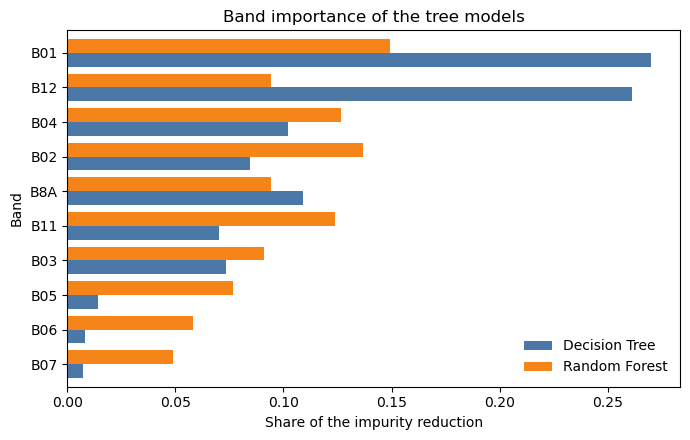

,Decision Tree,Random Forest
band,,
B01,0.270,0.149
B12,0.261,0.094
B04,0.102,0.127
B02,0.084,0.137
B8A,0.109,0.094
B11,0.070,0.124
B03,0.073,0.091
B05,0.014,0.077
B06,0.008,0.058


In [13]:
phase2_metrics = json.loads((OUTPUTS / "metrics.json").read_text())
client = mlflow.MlflowClient()
importance = {}
for entry in phase2_metrics["models"]:
    if entry["key"] in ("decision_tree", "random_forest"):
        # The model logged by the run, addressed by its id (models:/<id>).
        run = client.get_run(entry["mlflow_run_id"])
        logged = client.search_logged_models(experiment_ids=[run.info.experiment_id],
                                             filter_string=f"source_run_id = '{run.info.run_id}'")
        tree_model = mlflow.sklearn.load_model(f"models:/{logged[0].model_id}")
        importance[entry["model"]] = tree_model[-1].feature_importances_
band_importance = pd.DataFrame(importance, index=pd.Index(BANDS, name="band"))
band_importance.round(4).to_csv(OUTPUTS / "band_importance.csv")

order = band_importance.mean(axis=1).sort_values().index
figure, axis = plt.subplots(figsize=(7, 4.5))
band_importance.loc[order].plot.barh(ax=axis, width=0.8, color=["#4c78a8", "#f58518"])
axis.set(xlabel="Share of the impurity reduction", ylabel="Band",
         title="Band importance of the tree models")
axis.legend(loc="lower right", frameon=False)
figure.tight_layout()
figure.savefig(OUTPUTS / "band_importance.png", dpi=150)
plt.show()
band_importance.loc[order[::-1]].round(3)